# Disease Prediction from Clinical Symptoms — Clean Implementation
**Project:** Machine Learning Model for Disease Prediction Using Clinical Symptoms

**Data files (`/content/Drive/`):** `dataset.csv` (records: disease + up to 17 symptoms), `Symptom-severity.csv`, `symptom_Description.csv`, `symptom_precaution.csv`.

**Pipeline**
1. Load and explore the data
2. Clean the data and **remove duplicate records**
3. Visualise the cleaned data
4. Encode symptoms (multi-hot) and diseases (labels)
5. **80% / 20% stratified split** — training and test records are completely separate
6. **Feature selection** — keep the 30 most informative symptoms, chosen on the training set only
7. Train, tune and evaluate the **four best classifiers**: Logistic Regression, SVM, Neural Network (MLP), Random Forest
8. Select the final model.

In [22]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Libraries

In [23]:
import time, warnings
from functools import partial
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MultiLabelBinarizer, LabelEncoder, label_binarize
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score, confusion_matrix,
                             matthews_corrcoef, cohen_kappa_score, roc_auc_score)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
SEED = 42

**Explanation:** pandas/numpy handle the tables and arrays, matplotlib/seaborn draw the figures, and scikit-learn provides encoding, splitting, feature selection, the four classifiers and the metrics. `SEED = 42` makes every random step reproducible.

## 2. Loading the Data

In [24]:
FOLDER = "/content/drive/MyDrive/DiseaseDataset"
df          = pd.read_csv(f"{FOLDER}/dataset.csv")
severity    = pd.read_csv(f"{FOLDER}/Symptom-severity.csv")
description = pd.read_csv(f"{FOLDER}/symptom_Description.csv")
precaution  = pd.read_csv(f"{FOLDER}/symptom_precaution.csv")

for name, t in [("dataset", df), ("severity", severity), ("description", description), ("precaution", precaution)]:
    print(f"{name:<12} {t.shape}")
df.head()

dataset      (4920, 18)
severity     (133, 2)
description  (41, 2)
precaution   (41, 5)


,Disease,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Symptom_5,Symptom_6,Symptom_7,Symptom_8,Symptom_9,Symptom_10,Symptom_11,Symptom_12,Symptom_13,Symptom_14,Symptom_15,Symptom_16,Symptom_17
0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Fungal infection,itching,skin_rash,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Fungal infection,itching,skin_rash,nodal_skin_eruptions,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Explanation:** each CSV is read into a DataFrame and its shape (rows, columns) is printed to confirm it was loaded correctly.

## 3. Initial Exploration

In [25]:
symptom_cols = [c for c in df.columns if c.startswith("Symptom")]
print("Records            :", len(df))
print("Diseases           :", df["Disease"].nunique())
print("Symptom columns    :", len(symptom_cols))
print("Records per disease:", df["Disease"].value_counts().unique())
print("Exact duplicate rows (raw):", df.duplicated().sum())

Records            : 4920
Diseases           : 41
Symptom columns    : 17
Records per disease: [120]
Exact duplicate rows (raw): 4616


**Explanation:** the raw file has 4,920 records, 41 diseases and 17 symptom columns, with exactly 120 records per disease. The last line already shows that most rows are exact copies of other rows — the problem fixed in Section 4.

## 4. Data Cleaning
### 4.1 Fixing names and the severity file

In [26]:
for t in (df, description, precaution):
    t["Disease"] = t["Disease"].str.strip()

for c in symptom_cols:                                   # strip spaces at the ends and inside names
    df[c] = df[c].str.strip().str.replace(" ", "", regex=False)

severity["Symptom"] = severity["Symptom"].str.strip().str.replace(" ", "", regex=False)
severity = (severity[severity["Symptom"] != "prognosis"]         # 'prognosis' is not a symptom
            .drop_duplicates("Symptom", keep="first")             # 'fluid_overload' appears twice
            .reset_index(drop=True))

all_symptoms = set(pd.concat([df[c] for c in symptom_cols]).dropna())
print("Unique symptoms in dataset          :", len(all_symptoms))
print("Symptoms missing from severity file :", all_symptoms - set(severity["Symptom"]))
print("Severity file rows after cleaning   :", len(severity))

Unique symptoms in dataset          : 131
Symptoms missing from severity file : set()
Severity file rows after cleaning   : 131


**Explanation:**
- `.str.strip()` removes spaces at the start/end of names; `.str.replace(" ", "")` removes spaces inside names (e.g. `dischromic _patches` → `dischromic_patches`), so every symptom now matches the severity file.
- The severity file contained a non-symptom row (`prognosis`) and a duplicated symptom (`fluid_overload`, weights 6 and 4); after cleaning it has exactly the 131 symptoms used in the data.
- Empty symptom cells (NaN) are not missing data: they only mean the patient reported fewer than 17 symptoms.

### 4.2 Removing duplicate records
Each record is reduced to its disease and its **set** of symptoms (order ignored). Records with the same disease and the same symptom set are duplicates and only one copy is kept.

In [27]:
df["symptoms"] = df[symptom_cols].apply(lambda r: tuple(sorted(s for s in r if pd.notna(s))), axis=1)

n_before = len(df)
data = df[["Disease", "symptoms"]].drop_duplicates().reset_index(drop=True)
print("Records before:", n_before, "| duplicates removed:", n_before - len(data), "| unique records:", len(data))

# Consistency check: no symptom set may belong to two diseases
print("Symptom sets linked to more than one disease:", data.groupby("symptoms")["Disease"].nunique().gt(1).sum())

# How do the unique records of a disease differ from each other?
data["n_symptoms"] = data["symptoms"].str.len()
full = data.groupby("Disease")["symptoms"].apply(lambda s: set().union(*map(set, s)))
data["missing_from_full_list"] = [len(full[d] - set(s)) for d, s in zip(data["Disease"], data["symptoms"])]
print("Symptoms missing compared with the disease's full list:", data["missing_from_full_list"].value_counts().to_dict())
print("Unique records per disease: min", data["Disease"].value_counts().min(), "max", data["Disease"].value_counts().max())

Records before: 4920 | duplicates removed: 4616 | unique records: 304
Symptom sets linked to more than one disease: 0
Symptoms missing compared with the disease's full list: {1: 263, 0: 41}
Unique records per disease: min 5 max 10


**Explanation:**
- `tuple(sorted(...))` gives one canonical form per symptom set, so `[a, b]` and `[b, a]` count as the same record.
- `drop_duplicates()` removes **4,616 duplicate rows**; **304 unique records** remain (5 – 10 per disease). No symptom set is labelled with two different diseases.
- The last check shows the structure of the data: for every disease there is **one record with its full symptom list** and the other records are that list **with exactly one symptom missing**. This is why, with all 131 symptoms, every test record is still almost identical to a training record (see Section 7).

## 5. Visualising the Cleaned Data

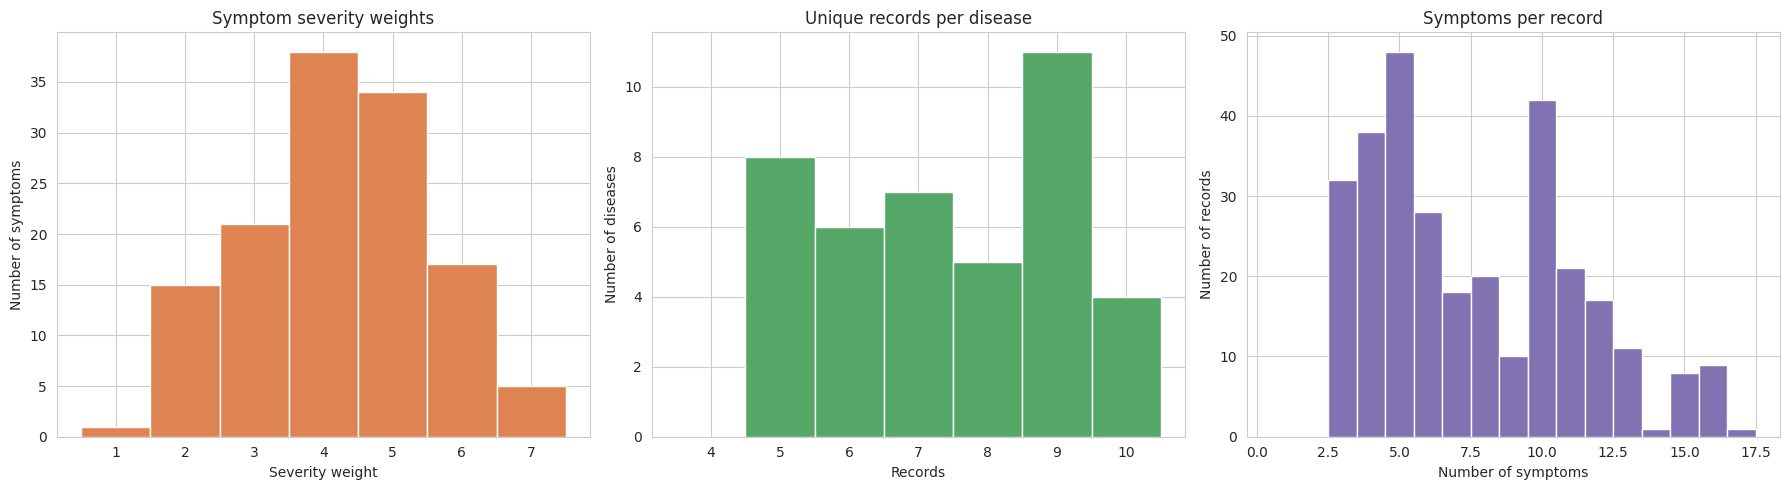

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(severity["weight"], bins=range(1, 9), align="left", color="#DD8452", edgecolor="white")
axes[0].set(title="Symptom severity weights", xlabel="Severity weight", ylabel="Number of symptoms")

counts = data["Disease"].value_counts()
axes[1].hist(counts, bins=range(4, 12), align="left", color="#55A868", edgecolor="white")
axes[1].set(title="Unique records per disease", xlabel="Records", ylabel="Number of diseases")

axes[2].hist(data["n_symptoms"], bins=range(1, 19), align="left", color="#8172B2", edgecolor="white")
axes[2].set(title="Symptoms per record", xlabel="Number of symptoms", ylabel="Number of records")
plt.tight_layout(); plt.show()

**Explanation:** (left) most symptoms have severity 3 – 5; (middle) after removing duplicates each disease has 5 – 10 records — a mild imbalance, handled with a stratified split and macro-averaged metrics rather than oversampling, which would re-create duplicates; (right) records have between 3 and 17 symptoms, most often 3 – 6 (single-symptom-removed variants of short lists) or about 10 (variants of long lists).

## 6. Encoding

In [29]:
mlb = MultiLabelBinarizer()
X = mlb.fit_transform(data["symptoms"])          # 304 × 131 binary matrix (1 = symptom present)
symptom_names = mlb.classes_

le = LabelEncoder()
y = le.fit_transform(data["Disease"])            # 41 disease labels -> 0 … 40
print("X:", X.shape, "| y:", y.shape, "| classes:", len(le.classes_))

X: (304, 131) | y: (304,) | classes: 41


**Explanation:** `MultiLabelBinarizer` turns each symptom list into a 131-long 0/1 vector (multi-hot encoding); `LabelEncoder` maps each disease name to an integer.

## 7. Train / Test Split (80% / 20%)

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Training records:", len(X_train), "| Test records:", len(X_test))

train_rows = set(map(bytes, X_train.astype(np.uint8)))
print("Test records identical to a training record:", sum(bytes(r) in train_rows for r in X_test.astype(np.uint8)))

# Similarity of each test record to its closest training record of the same disease (Jaccard)
def jaccard(a, b): return (a & b).sum() / (a | b).sum()
nearest = [max(jaccard(X_test[i], X_train[j]) for j in np.flatnonzero(y_train == y_test[i])) for i in range(len(X_test))]
print("Mean similarity of a test record to its closest training record: %.2f" % np.mean(nearest))

Training records: 243 | Test records: 61
Test records identical to a training record: 0
Mean similarity of a test record to its closest training record: 0.86


**Explanation:**
- `test_size=0.20` keeps 20% of the records for testing (61) and 80% for training (243); `stratify=y` keeps every disease in both sets.
- **No test record is identical to a training record**, so training and test sets are fully separate.
- However, the Jaccard similarity shows that each test record still shares about 85% of its symptoms with a training record of the same disease (the records differ by one symptom). With all 131 symptoms the diseases do not overlap at all, so any good model would reach 100%. Section 8 addresses this with feature selection.

## 8. Feature Selection — The 30 Most Informative Symptoms
In practice, a symptom checker asks the patient a **short list of questions**, not 131. We therefore keep only the **30 symptoms with the highest Mutual Information (MI)** with the disease. MI is computed **on the training set only**, and inside every cross-validation fold through a `Pipeline`, so no information from the test set is used.

With fewer symptoms, some diseases share the same visible symptoms, so the task becomes realistic and the models can be compared.

Selected symptoms: ['loss_of_appetite', 'fatigue', 'vomiting', 'high_fever', 'headache', 'abdominal_pain', 'nausea', 'yellowing_of_eyes', 'malaise', 'yellowish_skin', 'chills', 'joint_pain', 'chest_pain', 'skin_rash', 'sweating', 'irritability', 'muscle_pain', 'itching', 'excessive_hunger', 'diarrhoea', 'dark_urine', 'cough', 'lethargy', 'weight_loss', 'mild_fever', 'phlegm', 'breathlessness', 'swelled_lymph_nodes', 'blurred_and_distorted_vision', 'depression']


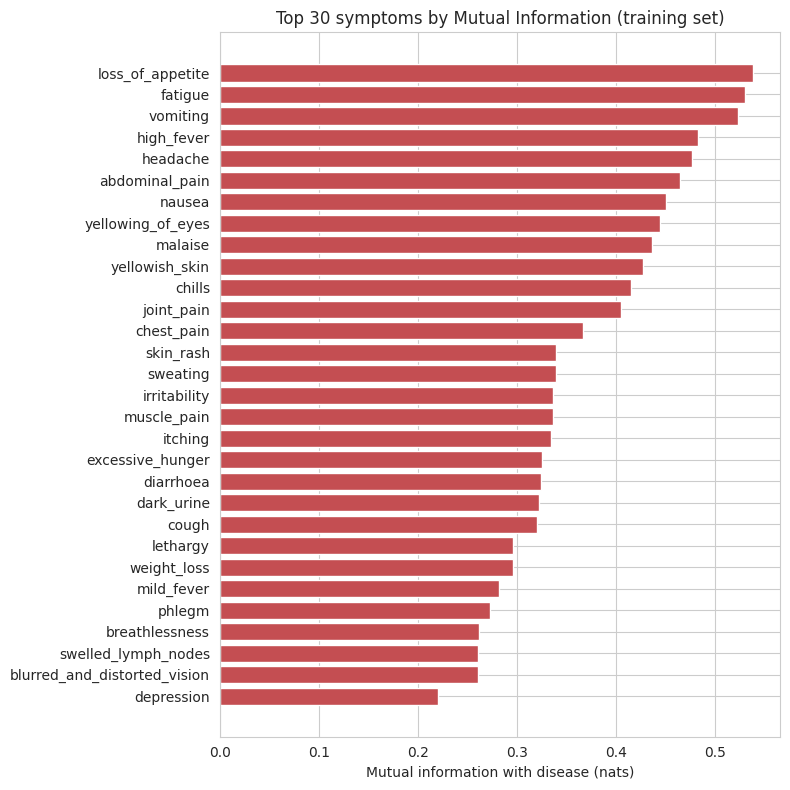

Training records that have none of the 30 symptoms: 23


In [31]:
N_FEATURES = 30
mi_score = partial(mutual_info_classif, discrete_features=True, random_state=SEED)

mi = pd.Series(mi_score(X_train, y_train), index=symptom_names).sort_values(ascending=False)
selected = mi.head(N_FEATURES)
print("Selected symptoms:", list(selected.index))

plt.figure(figsize=(8, 8))
plt.barh(selected.index[::-1], selected.values[::-1], color="#C44E52")
plt.xlabel("Mutual information with disease (nats)"); plt.title(f"Top {N_FEATURES} symptoms by Mutual Information (training set)")
plt.tight_layout(); plt.show()

X_sel = X_train[:, np.isin(symptom_names, selected.index)]
print("Training records that have none of the 30 symptoms:", (X_sel.sum(1) == 0).sum())

**Explanation:**
- `mutual_info_classif(..., discrete_features=True)` measures how much knowing whether a symptom is present reduces the uncertainty about the disease.
- The 30 highest-scoring symptoms are the general, frequently reported ones (fatigue, vomiting, high fever, …); rare, disease-specific symptoms are left out.
- `partial(...)` fixes the arguments so the same scoring function can be used inside `SelectKBest` in the pipeline.

### 8.1 Effect of the number of symptoms (cross-validation on the training set)

k =  10  CV macro-F1 = 0.4480
k =  20  CV macro-F1 = 0.6868
k =  30  CV macro-F1 = 0.7332
k =  40  CV macro-F1 = 0.8115
k =  60  CV macro-F1 = 0.8645
k =  90  CV macro-F1 = 0.9130
k = 131  CV macro-F1 = 1.0000


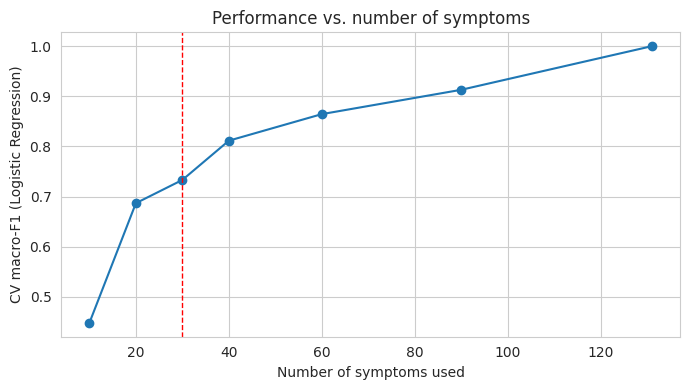

In [32]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
ks = [10, 20, 30, 40, 60, 90, 131]
cv_f1 = []
for k in ks:
    pipe = Pipeline([("select", SelectKBest(mi_score, k=k)), ("clf", LogisticRegression(max_iter=5000))])
    cv_f1.append(cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro").mean())
    print(f"k = {k:>3}  CV macro-F1 = {cv_f1[-1]:.4f}")

plt.figure(figsize=(7, 4)); plt.plot(ks, cv_f1, marker="o")
plt.axvline(N_FEATURES, color="red", ls="--", lw=1)
plt.xlabel("Number of symptoms used"); plt.ylabel("CV macro-F1 (Logistic Regression)")
plt.title("Performance vs. number of symptoms"); plt.tight_layout(); plt.show()

**Explanation:** with all 131 symptoms the score is (almost) perfect because the diseases are fully separable in this dataset; it drops as fewer symptoms are available. **30 symptoms** (red line) is used as a practical questionnaire size that keeps a high score while giving a realistic, non-trivial evaluation.

## 9. The Four Classifiers and Hyperparameter Tuning
Each model is a `Pipeline`: **SelectKBest (30 symptoms, MI)** → **classifier**. Hyperparameters are tuned with `GridSearchCV` (3-fold stratified CV, macro F1) on the training set only. 3 folds are used because the smallest disease has only 4 training records.

In [33]:
def make_pipe(clf):
    return Pipeline([("select", SelectKBest(mi_score, k=N_FEATURES)), ("clf", clf)])

search_space = {
    "Logistic Regression":  (LogisticRegression(max_iter=5000),            {"clf__C": [0.1, 1, 10, 100]}),
    "SVM":                  (SVC(probability=True, random_state=SEED),    {"clf__kernel": ["linear", "rbf"], "clf__C": [0.1, 1, 10]}),
    "Neural Network (MLP)": (MLPClassifier(max_iter=2000, random_state=SEED),
                             {"clf__hidden_layer_sizes": [(64,), (128, 64)], "clf__alpha": [1e-4, 1e-2]}),
    "Random Forest":        (RandomForestClassifier(random_state=SEED, n_jobs=-1),
                             {"clf__n_estimators": [200, 500], "clf__max_features": ["sqrt", "log2"]}),
}

models, tuning = {}, []
for name, (clf, grid) in search_space.items():
    gs = GridSearchCV(make_pipe(clf), grid, cv=cv, scoring="f1_macro", n_jobs=-1).fit(X_train, y_train)
    models[name] = gs.best_estimator_
    tuning.append({"Model": name, "Best parameters": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
                   "CV macro-F1": round(gs.best_score_, 4)})
pd.DataFrame(tuning).set_index("Model")

,Best parameters,CV macro-F1
Model,,
Logistic Regression,{'C': 10},0.7452
SVM,"{'C': 10, 'kernel': 'rbf'}",0.7408
Neural Network (MLP),"{'alpha': 0.0001, 'hidden_layer_sizes': (64,)}",0.7495
Random Forest,"{'max_features': 'log2', 'n_estimators': 500}",0.7585


**Explanation:**
- **Logistic Regression** — softmax model with one weight per symptom and disease; `C` controls regularisation.
- **SVM** — maximum-margin classifier; linear vs RBF kernel and `C` are tested; `probability=True` gives class probabilities for ROC-AUC.
- **MLP** — neural network with one or two hidden layers; `alpha` is the L2 penalty.
- **Random Forest** — ensemble of decision trees; number of trees and `max_features` are tested.
- The `clf__` prefix tells the pipeline which step a parameter belongs to.

## 10. Evaluation on the Test Set

In [34]:
classes = np.arange(len(le.classes_))

def specificity_macro(cm):
    tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp; tn = cm.sum() - tp - fp - fn
    return np.mean(tn / (tn + fp))

def evaluate(name, model, Xtr, ytr, Xte, yte):
    t0 = time.time(); model.fit(Xtr, ytr); t_train = time.time() - t0
    t0 = time.time(); pred = model.predict(Xte); t_pred = time.time() - t0
    proba = model.predict_proba(Xte)
    p, r, f1, _ = precision_recall_fscore_support(yte, pred, average="macro", zero_division=0)
    cm = confusion_matrix(yte, pred, labels=classes)
    present = np.unique(yte)
    auc = roc_auc_score(label_binarize(yte, classes=classes)[:, present], proba[:, present], average="macro")
    return {"Model": name, "Accuracy": accuracy_score(yte, pred), "Precision": p, "Recall": r,
            "Specificity": specificity_macro(cm), "F1-score": f1, "MCC": matthews_corrcoef(yte, pred),
            "Kappa": cohen_kappa_score(yte, pred), "ROC-AUC": auc, "Errors": int((pred != yte).sum()),
            "Train time (s)": t_train, "Predict time (s)": t_pred}, cm, pred

results, cms, preds = [], {}, {}
for name, model in models.items():
    row, cm, pred = evaluate(name, model, X_train, y_train, X_test, y_test)
    results.append(row); cms[name] = cm; preds[name] = pred

test_table = pd.DataFrame(results).set_index("Model").sort_values(["F1-score", "Accuracy"], ascending=False)
test_table.round(4)

,Accuracy,Precision,Recall,Specificity,F1-score,MCC,Kappa,ROC-AUC,Errors,Train time (s),Predict time (s)
Model,,,,,,,,,,,
Neural Network (MLP),0.9016,0.8138,0.8537,0.9976,0.8244,0.9019,0.8989,0.9941,6,1.9422,0.0031
Logistic Regression,0.8852,0.8057,0.8415,0.9971,0.8114,0.8852,0.8820,0.9945,7,0.3866,0.0012
SVM,0.8689,0.7610,0.8171,0.9967,0.7764,0.8683,0.8652,0.9896,8,0.7528,0.0051
Random Forest,0.8525,0.7407,0.8049,0.9963,0.7593,0.8523,0.8483,0.9803,9,1.8022,0.1409


**Explanation:**
- All class-level metrics are **macro averages** over the 41 diseases, so every disease has equal weight.
- **Specificity** = TN / (TN + FP), computed from the confusion matrix (scikit-learn has no direct function).
- **ROC-AUC** (one-vs-rest) is computed over the diseases present in the test set.
- Training and prediction times measure the computational cost.

### 10.1 Confusion matrices and misclassified records

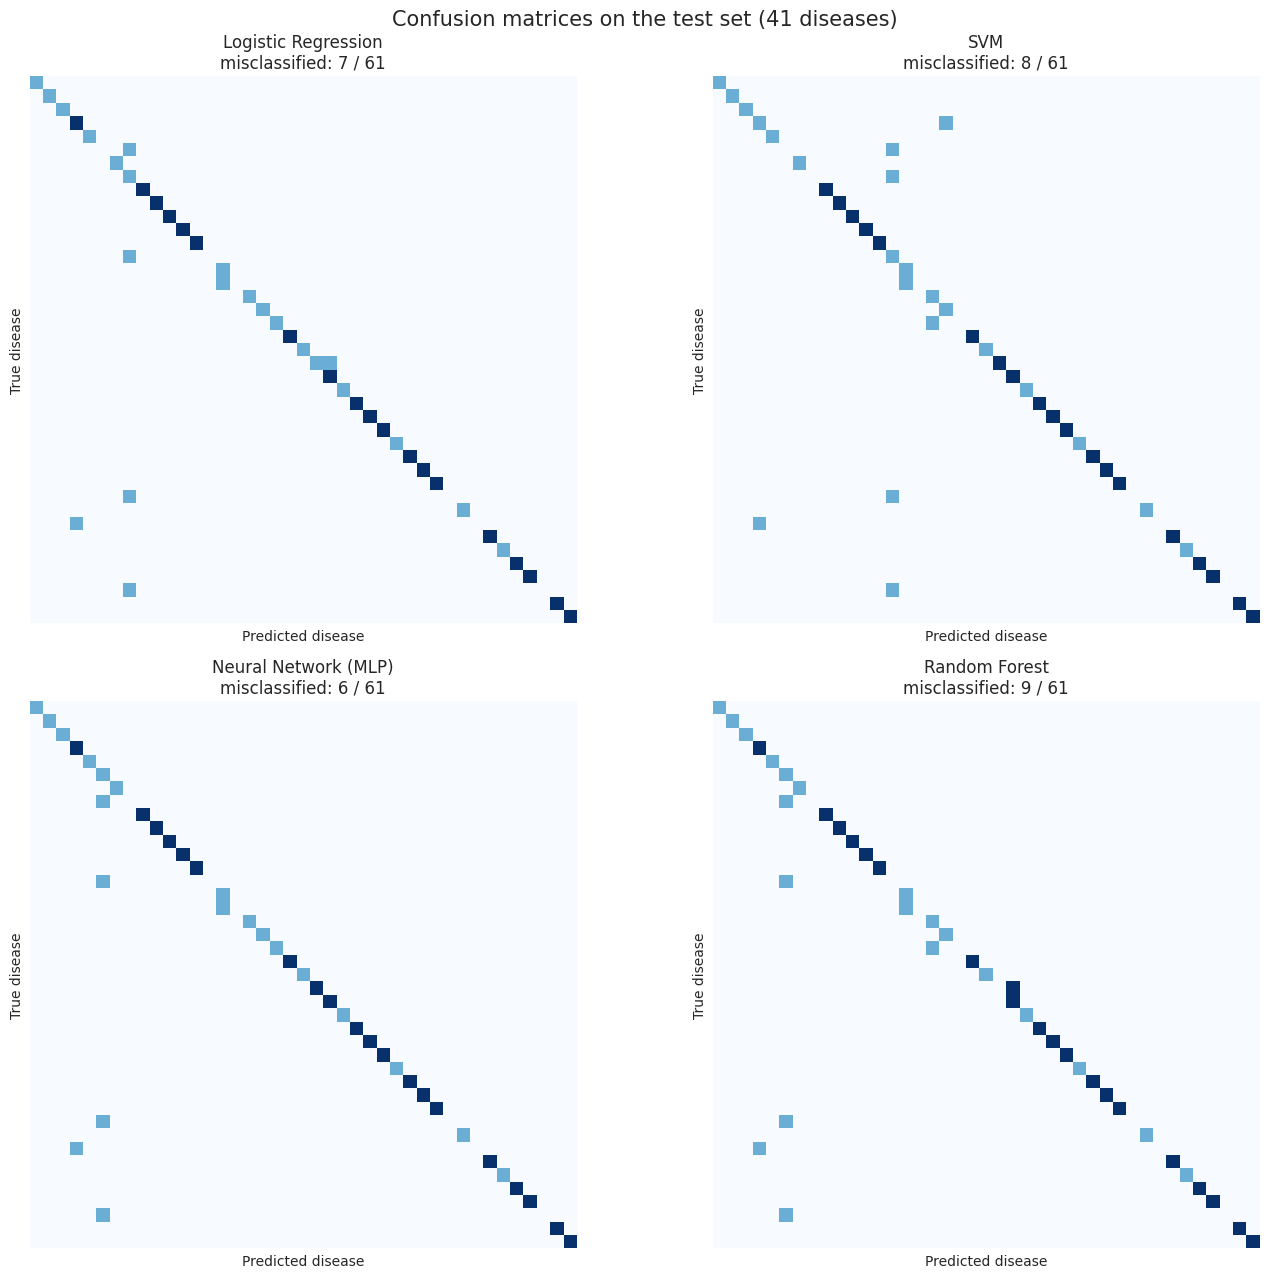

Test records with none of the 30 selected symptoms: 5


,,Errors (all four models)
True disease,Predicted,
Fungal infection,Drug Reaction,4
Peptic ulcer diseae,Alcoholic hepatitis,4
Hepatitis D,Hepatitis E,3
Osteoarthristis,Arthritis,2
Cervical spondylosis,Arthritis,2
Dimorphic hemmorhoids(piles),Arthritis,2
Urinary tract infection,Arthritis,2
Heart attack,GERD,2
Alcoholic hepatitis,Gastroenteritis,1


In [35]:
fig, axes = plt.subplots(2, 2, figsize=(14, 13))
for ax, (name, cm) in zip(axes.ravel(), cms.items()):
    sns.heatmap(cm, cmap="Blues", cbar=False, square=True, ax=ax, xticklabels=False, yticklabels=False)
    ax.set_title(f"{name}\nmisclassified: {cm.sum() - np.trace(cm)} / {cm.sum()}")
    ax.set_xlabel("Predicted disease"); ax.set_ylabel("True disease")
plt.suptitle("Confusion matrices on the test set (41 diseases)", fontsize=15)
plt.tight_layout(); plt.show()

errors = pd.DataFrame([{"Model": n, "True disease": le.classes_[t], "Predicted": le.classes_[p]}
                       for n, pr in preds.items() for t, p in zip(y_test, pr) if t != p])
sel_mask = np.isin(symptom_names, selected.index)
print("Test records with none of the 30 selected symptoms:", int((X_test[:, sel_mask].sum(1) == 0).sum()))
errors.value_counts(["True disease", "Predicted"]).rename("Errors (all four models)").to_frame()

**Explanation:** correct predictions lie on the diagonal of each matrix. The table lists each type of error and how many times it occurred across the four models. The last line counts the test records that contain **none** of the 30 selected symptoms — no model can classify these correctly.

### 10.2 Stability: 10 repeated 80/20 splits
With 61 test records, one error changes accuracy by 1.6 points. The whole procedure (split → feature selection → training with the tuned settings → testing) is repeated with 10 different seeds.

In [ ]:
rep = {n: {"acc": [], "f1": []} for n in models}
for seed in range(10):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, stratify=y, random_state=seed)
    for n, m in models.items():
        p = clone(m).fit(Xtr, ytr).predict(Xte)
        rep[n]["acc"].append(accuracy_score(yte, p)); rep[n]["f1"].append(f1_score(yte, p, average="macro"))

stability = pd.DataFrame({n: {"Accuracy mean": np.mean(v["acc"]), "Accuracy std": np.std(v["acc"]),
                              "F1 mean": np.mean(v["f1"]), "F1 std": np.std(v["f1"])} for n, v in rep.items()}).T
stability = stability.sort_values("F1 mean", ascending=False)

plt.figure(figsize=(8, 4.5))
plt.boxplot([rep[n]["acc"] for n in stability.index], tick_labels=list(stability.index))
plt.ylabel("Test accuracy"); plt.title("Accuracy over 10 repeated 80/20 splits")
plt.tight_layout(); plt.show()
stability.round(4)

**Explanation:** `clone` creates an untrained copy with the same tuned settings for each repetition; the mean ± standard deviation shows how much the result depends on the particular split.

## 11. Final Comparison

In [ ]:
final = test_table.join(stability).sort_values("F1 mean", ascending=False)
final.round(4).to_csv("model_comparison.csv")
final.round(4)

## 12. The Selected Model — Logistic Regression
The weights of Logistic Regression show which of the 30 symptoms push the model towards each disease, and its probabilities give a ranked list of likely diseases for a new patient.

In [ ]:
final_model = models["Logistic Regression"]
used = symptom_names[final_model.named_steps["select"].get_support()]
coef = pd.DataFrame(final_model.named_steps["clf"].coef_, index=le.classes_, columns=used)
for d in ["Diabetes", "Malaria", "Hypothyroidism"]:
    top = coef.loc[d].sort_values(ascending=False).head(4)
    print(f"{d:<15}: " + ", ".join(f"{s} ({w:.2f})" for s, w in top.items()))

patient = ["high_fever", "chills", "sweating", "headache", "muscle_pain"]
proba = final_model.predict_proba(mlb.transform([patient]))[0]
print("\nNew patient:", patient)
for k in np.argsort(proba)[::-1][:3]:
    print(f"   {le.classes_[k]:<25} {proba[k]:.3f}")

**Explanation:** `named_steps["select"].get_support()` returns which symptoms the pipeline kept; `coef_` holds one weight per (disease, symptom). `predict_proba` returns the probability of every disease, and the three most likely diseases are shown — a decision-support output for a clinician, together with the disease description and precautions files.